In [1]:
import pandas as pd

prices = pd.read_csv(
    "clean_prices.csv",
    index_col=0,
    parse_dates=True
)

print(prices.shape)
prices.head()

(1674, 485)


,A,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,ADM,ADP,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2020-03-19,62.684689,58.995003,54.523285,65.662354,25.731314,141.681076,307.510010,80.812080,27.803530,101.647743,...,12.775620,44.948299,47.427483,25.913141,59.542938,40.000000,55.394783,81.762215,185.070007,95.268188
2020-03-20,63.351948,55.249683,52.804562,59.933437,24.694834,134.029419,295.339996,76.123695,25.435328,97.049049,...,11.683282,50.149479,41.408062,24.641180,55.321529,38.090000,51.395035,78.863762,179.380005,93.974129
2020-03-23,60.406448,54.075943,49.489902,55.367897,22.117901,128.442612,307.269989,76.195274,24.355093,94.459610,...,10.662185,55.553322,40.892803,23.670286,52.319458,40.009998,50.014591,74.121651,170.720001,86.265495
2020-03-24,63.866684,59.501125,51.784084,61.422935,24.343002,140.206192,310.000000,83.863136,26.856247,104.756859,...,13.361368,64.228394,44.205128,26.673288,57.270576,46.310001,61.642208,85.669609,180.550003,96.599487
2020-03-25,65.773140,59.173355,52.106350,62.357201,24.457109,135.709915,305.910004,84.426788,27.172012,106.168503,...,14.026268,72.430649,45.431911,28.065664,58.988701,52.389999,64.482719,88.815727,186.229996,100.742386


In [2]:
train = prices.loc[:"2024-12-31"].copy()
test = prices.loc["2025-01-01":].copy()

print("Training:", train.shape)
print("Testing:", test.shape)

Training: (1205, 485)
Testing: (469, 485)


In [3]:
from statsmodels.tsa.stattools import coint

stock_a = train["AAPL"]
stock_b = train["MSFT"]

test_stat, p_value, critical_values = coint(stock_a, stock_b)

print("Test statistic:", test_stat)
print("P-value:", p_value)
print("Critical values:", critical_values)

Test statistic: -2.0220204478002684
P-value: 0.5171140944059849
Critical values: [-3.90555939 -3.34120954 -3.04797447]


In [4]:
from itertools import combinations

tickers = train.columns.tolist()

pairs = list(combinations(tickers, 2))

print("Number of stocks:", len(tickers))
print("Number of pairs:", len(pairs))
print("First 10 pairs:", pairs[:10])

Number of stocks: 485
Number of pairs: 117370
First 10 pairs: [('A', 'AAPL'), ('A', 'ABBV'), ('A', 'ABT'), ('A', 'ACGL'), ('A', 'ACN'), ('A', 'ADBE'), ('A', 'ADI'), ('A', 'ADM'), ('A', 'ADP'), ('A', 'ADSK')]


In [6]:

from statsmodels.tsa.stattools import coint

def test_cointegration(ticker_a, ticker_b):
    stock_a = train[ticker_a]
    stock_b = train[ticker_b]

    test_stat, p_value, critical_values = coint(stock_a, stock_b)

    return {
        "Stock A": ticker_a,
        "Stock B": ticker_b,
        "Test Statistic": test_stat,
        "P-value": p_value
    }


In [7]:

results = []

for ticker_a, ticker_b in pairs[:10]:
    result = test_cointegration(ticker_a, ticker_b)
    results.append(result)

results_df = pd.DataFrame(results)

results_df.sort_values("P-value")


,Stock A,Stock B,Test Statistic,P-value
3,A,ACGL,-2.976309,0.115945
2,A,ABT,-2.804201,0.164352
1,A,ABBV,-2.762691,0.177845
5,A,ADBE,-2.724117,0.191025
7,A,ADM,-2.646677,0.219340
6,A,ADI,-2.560141,0.253208
8,A,ADP,-2.529369,0.266272
9,A,ADSK,-2.522724,0.269140
0,A,AAPL,-2.431241,0.310205
4,A,ACN,-2.410381,0.319954


In [8]:
import time

start_time = time.time()

results = []

for ticker_a, ticker_b in pairs[:100]:
    result = test_cointegration(ticker_a, ticker_b)
    results.append(result)

results_df = pd.DataFrame(results)

elapsed_time = time.time() - start_time

print("Pairs tested:", len(results_df))
print("Time elapsed:", round(elapsed_time, 2), "seconds")

results_df.sort_values("P-value").head(10)


Pairs tested: 100
Time elapsed: 2.79 seconds


,Stock A,Stock B,Test Statistic,P-value
54,A,BEN,-3.499655,0.032426
90,A,CLX,-3.321899,0.051796
82,A,CFG,-3.286547,0.056607
88,A,CINF,-3.260246,0.060417
48,A,BAC,-3.258434,0.060687
55,A,BF-B,-3.214612,0.067518
42,A,AVY,-3.183705,0.072695
21,A,ALLE,-3.178240,0.073643
50,A,BAX,-3.136854,0.081138
85,A,CHTR,-3.135504,0.081392


In [9]:
import os
import time
import pandas as pd

batch_size = 1000
os.makedirs("cointegration_batches", exist_ok=True)

start_time = time.time()

for start in range(0, len(pairs), batch_size):

    end = min(start + batch_size, len(pairs))
    filename = f"cointegration_batches/batch_{start}_{end}.csv"

    if os.path.exists(filename):
        print("Already completed:", filename)
        continue

    batch_results = []

    for ticker_a, ticker_b in pairs[start:end]:
        result = test_cointegration(ticker_a, ticker_b)
        batch_results.append(result)

    batch_df = pd.DataFrame(batch_results)
    batch_df.to_csv(filename, index=False)

    print(f"Completed {end}/{len(pairs)} pairs")

print("Total time:", round(time.time() - start_time, 2), "seconds")


Completed 1000/117370 pairs
Completed 2000/117370 pairs
Completed 3000/117370 pairs
Completed 4000/117370 pairs
Completed 5000/117370 pairs
Completed 6000/117370 pairs
Completed 7000/117370 pairs
Completed 8000/117370 pairs
Completed 9000/117370 pairs
Completed 10000/117370 pairs
Completed 11000/117370 pairs
Completed 12000/117370 pairs
Completed 13000/117370 pairs
Completed 14000/117370 pairs
Completed 15000/117370 pairs
Completed 16000/117370 pairs
Completed 17000/117370 pairs
Completed 18000/117370 pairs
Completed 19000/117370 pairs
Completed 20000/117370 pairs
Completed 21000/117370 pairs
Completed 22000/117370 pairs
Completed 23000/117370 pairs
Completed 24000/117370 pairs
Completed 25000/117370 pairs
Completed 26000/117370 pairs
Completed 27000/117370 pairs
Completed 28000/117370 pairs
Completed 29000/117370 pairs
Completed 30000/117370 pairs
Completed 31000/117370 pairs
Completed 32000/117370 pairs
Completed 33000/117370 pairs
Completed 34000/117370 pairs
Completed 35000/117370 

In [10]:
import glob
import pandas as pd
files = glob.glob("cointegration_batches/batch_*.csv")
print("Number of files:", len(files))
all_results = []
for file in files:
    df = pd.read_csv(file)
    all_results.append(df)
results_df = pd.concat(all_results, ignore_index=True)
print("Total pairs:", len(results_df))
print("Duplicate pairs:", results_df.duplicated(
    subset=["Stock A", "Stock B"]
).sum())
print("Missing p-values:", results_df["P-value"].isna().sum())
results_df.sort_values("P-value").head(10)

Number of files: 118
Total pairs: 117370
Duplicate pairs: 0
Missing p-values: 0


,Stock A,Stock B,Test Statistic,P-value
13532,MA,PH,-6.259049,4.392948e-07
70319,CHRW,WEC,-6.188620,6.292161e-07
90035,CRH,MA,-6.055095,1.233601e-06
77976,AVGO,FIX,-6.046994,1.284590e-06
117138,ABT,NSC,-5.739985,5.780954e-06
81370,DGX,MS,-5.642101,9.216045e-06
50465,PPL,WMT,-5.633986,9.576488e-06
6680,BDX,VZ,-5.508825,1.720307e-05
81422,DGX,PM,-5.496064,1.825017e-05
90202,CRH,V,-5.483251,1.936332e-05


In [11]:
from statsmodels.stats.multitest import multipletests
original_count = (results_df["P-value"] < 0.05).sum()
rejected, adjusted_p, _, _ = multipletests(
    results_df["P-value"],
    alpha=0.05,
    method="fdr_bh"
)
results_df["Adjusted P-value"] = adjusted_p
results_df["Significant"] = rejected
significant_pairs = results_df[
    results_df["Significant"]
].sort_values("Adjusted P-value")
print("Original significant pairs:", original_count)
print("After BH correction:", len(significant_pairs))
significant_pairs.head(10)

Original significant pairs: 10530
After BH correction: 4


,Stock A,Stock B,Test Statistic,P-value,Adjusted P-value,Significant
13532,MA,PH,-6.259049,4.392948e-07,0.036926,True
70319,CHRW,WEC,-6.188620,6.292161e-07,0.036926,True
77976,AVGO,FIX,-6.046994,1.284590e-06,0.037693,True
90035,CRH,MA,-6.055095,1.233601e-06,0.037693,True


In [12]:
import statsmodels.api as sm

y = train["MA"]
x = train["PH"]

X = sm.add_constant(x)

model = sm.OLS(y, X).fit()

print(model.params)

const    214.644132
PH         0.455027
dtype: float64


Hedge ratio: 0.45502662081966005
Spread mean: -5.698493774593866e-14
Spread standard deviation: 15.100552199902594


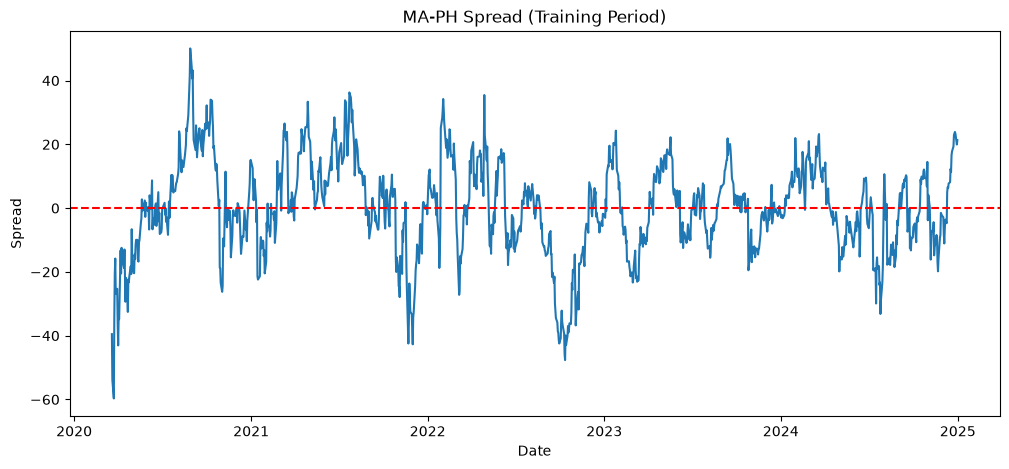

In [14]:
import matplotlib.pyplot as plt

alpha = model.params["const"]
beta = model.params["PH"]

spread = y - alpha - beta * x

print("Hedge ratio:", beta)
print("Spread mean:", spread.mean())
print("Spread standard deviation:", spread.std())

plt.figure(figsize=(12, 5))
plt.plot(spread.index, spread)
plt.axhline(spread.mean(), color="red", linestyle="--")
plt.title("MA-PH Spread (Training Period)")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.show()

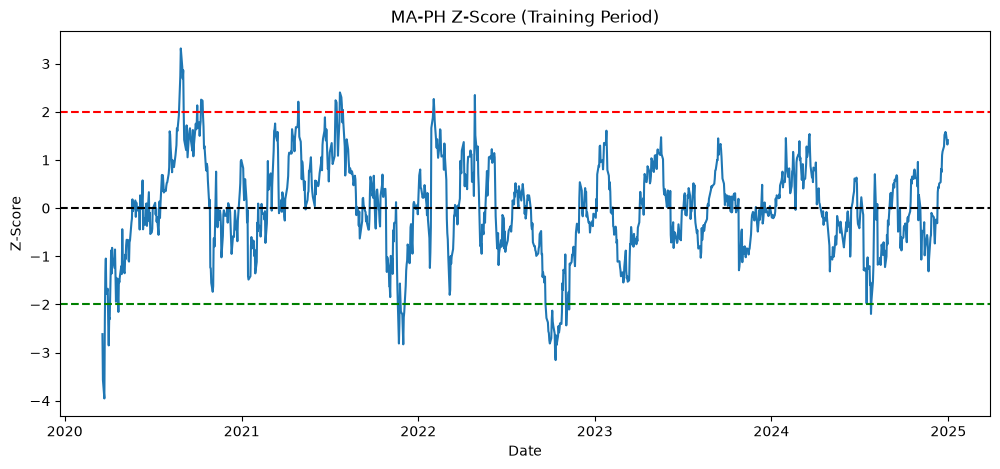

In [15]:
spread_mean = spread.mean()
spread_std = spread.std()

z_score = (spread - spread_mean) / spread_std

plt.figure(figsize=(12, 5))
plt.plot(z_score.index, z_score)
plt.axhline(0, color="black", linestyle="--")
plt.axhline(2, color="red", linestyle="--")
plt.axhline(-2, color="green", linestyle="--")
plt.title("MA-PH Z-Score (Training Period)")
plt.xlabel("Date")
plt.ylabel("Z-Score")
plt.show()

In [16]:
long_entry = (z_score < -2) & (z_score.shift(1) >= -2)
short_entry = (z_score > 2) & (z_score.shift(1) <= 2)

print("Long entry signals:", long_entry.sum())
print("Short entry signals:", short_entry.sum())

print("Long entry dates:")
print(z_score[long_entry])

print("Short entry dates:")
print(z_score[short_entry])


Long entry signals: 8
Short entry signals: 9
Long entry dates:
Date
2020-03-31   -2.402224
2020-04-21   -2.155637
2021-11-22   -2.811797
2021-11-26   -2.147271
2022-09-22   -2.139957
2022-11-03   -2.435316
2022-11-09   -2.104793
2024-07-25   -2.197604
dtype: float64
Short entry dates:
Date
2020-08-25    2.187443
2020-10-01    2.133918
2020-10-09    2.252481
2021-04-28    2.209912
2021-07-14    2.239917
2021-07-23    2.402057
2021-07-29    2.041543
2022-02-01    2.035139
2022-04-28    2.348675
dtype: float64


In [17]:
position = 0
positions = []

for z in z_score:
    if position == 0:
        if z < -2:
            position = 1
        elif z > 2:
            position = -1

    elif position == 1:
        if z >= 0:
            position = 0

    elif position == -1:
        if z <= 0:
            position = 0

    positions.append(position)

positions = pd.Series(positions, index=z_score.index)

print(positions.value_counts())

 0    975
 1    117
-1    113
Name: count, dtype: int64


In [18]:
previous_positions = positions.shift(1).fillna(0)

entries = (positions != 0) & (previous_positions == 0)
exits = (positions == 0) & (previous_positions != 0)

print("Number of entries:", entries.sum())
print("Number of exits:", exits.sum())

print("Entry dates:")
print(positions[entries])

print("Exit dates:")
print(positions[exits])


Number of entries: 9
Number of exits: 9
Entry dates:
Date
2020-03-19    1
2020-08-25   -1
2021-04-28   -1
2021-07-14   -1
2021-11-22    1
2022-02-01   -1
2022-04-28   -1
2022-09-22    1
2024-07-25    1
dtype: int64
Exit dates:
Date
2020-05-20    0
2020-10-28    0
2021-05-13    0
2021-08-26    0
2021-12-22    0
2022-03-01    0
2022-05-09    0
2022-11-30    0
2024-08-01    0
dtype: int64


In [19]:
entry_dates = positions.index[entries]
exit_dates = positions.index[exits]

trades = []

for entry_date, exit_date in zip(entry_dates, exit_dates):
    direction = positions.loc[entry_date]

    holding_days = positions.index.get_loc(exit_date) - positions.index.get_loc(entry_date)

    trades.append({
        "Entry Date": entry_date,
        "Exit Date": exit_date,
        "Direction": direction,
        "Entry Z-score": z_score.loc[entry_date],
        "Exit Z-score": z_score.loc[exit_date],
        "Holding Days": holding_days
    })

trade_log = pd.DataFrame(trades)

trade_log

,Entry Date,Exit Date,Direction,Entry Z-score,Exit Z-score,Holding Days
0,2020-03-19,2020-05-20,1,-2.617227,0.181927,43
1,2020-08-25,2020-10-28,-1,2.187443,-1.235573,45
2,2021-04-28,2021-05-13,-1,2.209912,-0.027149,11
3,2021-07-14,2021-08-26,-1,2.239917,-0.145438,31
4,2021-11-22,2021-12-22,1,-2.811797,0.083271,21
5,2022-02-01,2022-03-01,-1,2.035139,-0.215904,19
6,2022-04-28,2022-05-09,-1,2.348675,-0.781071,7
7,2022-09-22,2022-11-30,1,-2.139957,0.212284,48
8,2024-07-25,2024-08-01,1,-2.197604,0.257939,5


Hedge Ratio: 0.455
Number of trades: 3
Initial capital: 797.46
Gross P&L: 122.99
Transaction costs: 5.85
Net P&L: 117.14
Total return: 14.69 %
Win rate: 100.0 %
Average holding days: 145.67


,Entry Date,Exit Date,Direction,Holding Days,Gross P&L,Transaction Cost,Net P&L
0,2025-01-28,2025-10-30,-1,191,42.354308,1.738175,40.616133
1,2025-11-07,2026-10-23,1,240,56.211702,1.952793,54.258909
2,2026-11-05,2026-11-13,-1,6,24.421773,2.157138,22.264635


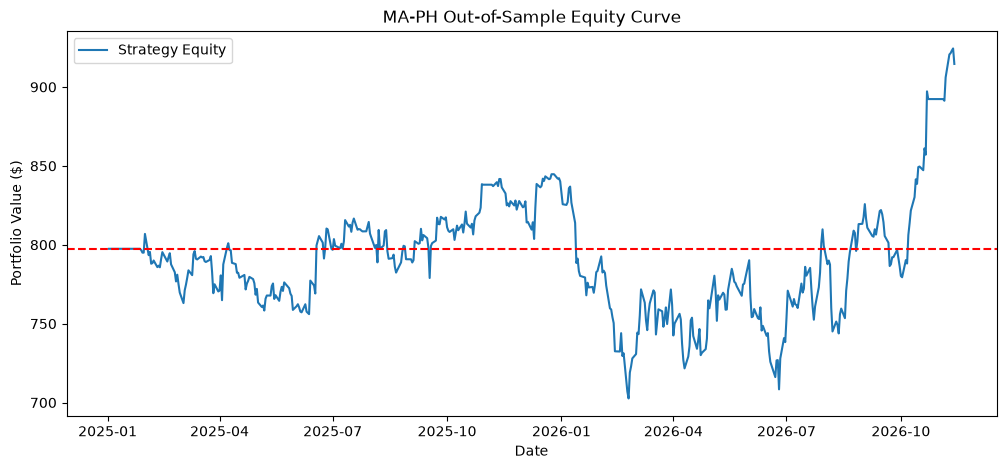

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

y_train = train["MA"]
x_train = train["PH"]

model = sm.OLS(y_train, sm.add_constant(x_train)).fit()

alpha = model.params["const"]
beta = model.params["PH"]

train_spread = y_train - alpha - beta * x_train
spread_mean = train_spread.mean()
spread_std = train_spread.std()

test_y = test["MA"]
test_x = test["PH"]

test_spread = test_y - alpha - beta * test_x
test_z = (test_spread - spread_mean) / spread_std

entry_threshold = 2
exit_threshold = 0
transaction_cost_rate = 0.001

position = 0
signal_positions = []

for z in test_z:
    if position == 0:
        if z < -entry_threshold:
            position = 1
        elif z > entry_threshold:
            position = -1

    elif position == 1:
        if z >= exit_threshold:
            position = 0

    elif position == -1:
        if z <= -exit_threshold:
            position = 0

    signal_positions.append(position)

signal_positions = pd.Series(
    signal_positions,
    index=test.index
)

actual_positions = signal_positions.shift(1).fillna(0).astype(int)
actual_positions.iloc[-1] = 0

previous_positions = actual_positions.shift(1).fillna(0)

daily_spread_change = test_spread.diff().fillna(0)

gross_pnl = previous_positions * daily_spread_change

position_changes = actual_positions - previous_positions

daily_notional = test_y + abs(beta) * test_x

transaction_costs = (
    position_changes.abs()
    * daily_notional
    * transaction_cost_rate
)

net_pnl = gross_pnl - transaction_costs

initial_capital = daily_notional.iloc[0]
equity = initial_capital + net_pnl.cumsum()

daily_results = pd.DataFrame({
    "Z-score": test_z,
    "Position": actual_positions,
    "Gross P&L": gross_pnl,
    "Transaction Cost": transaction_costs,
    "Net P&L": net_pnl,
    "Equity": equity
})

entries = (actual_positions != 0) & (previous_positions == 0)
exits = (actual_positions == 0) & (previous_positions != 0)

entry_dates = actual_positions.index[entries]
exit_dates = actual_positions.index[exits]

trades = []

for entry_date, exit_date in zip(entry_dates, exit_dates):
    direction = actual_positions.loc[entry_date]

    entry_spread = test_spread.loc[entry_date]
    exit_spread = test_spread.loc[exit_date]

    holding_days = (
        test.index.get_loc(exit_date)
        - test.index.get_loc(entry_date)
    )

    trade_gross_pnl = direction * (exit_spread - entry_spread)

    trade_cost = transaction_cost_rate * (
        daily_notional.loc[entry_date]
        + daily_notional.loc[exit_date]
    )

    trade_net_pnl = trade_gross_pnl - trade_cost

    trades.append({
        "Entry Date": entry_date,
        "Exit Date": exit_date,
        "Direction": direction,
        "Holding Days": holding_days,
        "Gross P&L": trade_gross_pnl,
        "Transaction Cost": trade_cost,
        "Net P&L": trade_net_pnl
    })

test_trade_log = pd.DataFrame(trades)

total_return = net_pnl.sum() / initial_capital * 100

print("Hedge Ratio:", round(beta, 4))
print("Number of trades:", len(test_trade_log))
print("Initial capital:", round(initial_capital, 2))
print("Gross P&L:", round(gross_pnl.sum(), 2))
print("Transaction costs:", round(transaction_costs.sum(), 2))
print("Net P&L:", round(net_pnl.sum(), 2))
print("Total return:", round(total_return, 2), "%")

if not test_trade_log.empty:
    print("Win rate:", round(
        (test_trade_log["Net P&L"] > 0).mean() * 100, 2
    ), "%")
    print("Average holding days:", round(
        test_trade_log["Holding Days"].mean(), 2
    ))

    assert np.isclose(
        test_trade_log["Net P&L"].sum(),
        net_pnl.sum()
    )

display(test_trade_log)

plt.figure(figsize=(12, 5))
plt.plot(equity.index, equity, label="Strategy Equity")
plt.axhline(initial_capital, color="red", linestyle="--")
plt.title("MA-PH Out-of-Sample Equity Curve")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.show()

Maximum Drawdown: -16.82 %


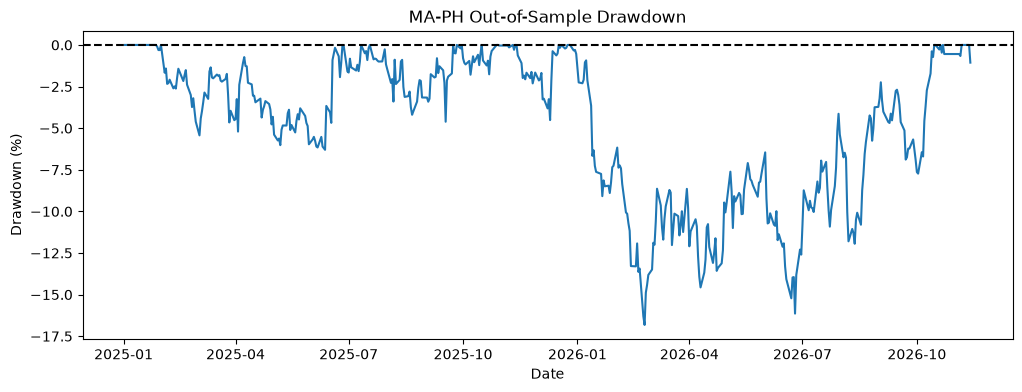

In [21]:
running_peak = equity.cummax()

drawdown = (equity - running_peak) / running_peak

max_drawdown = drawdown.min()

print("Maximum Drawdown:", round(max_drawdown * 100, 2), "%")

plt.figure(figsize=(12, 4))
plt.plot(drawdown.index, drawdown * 100)
plt.axhline(0, color="black", linestyle="--")
plt.title("MA-PH Out-of-Sample Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.show()

In [22]:
daily_returns = equity.pct_change().fillna(0)

trading_days = len(equity) - 1

annualized_return = (equity.iloc[-1] / initial_capital) ** (252 / trading_days) - 1

annualized_volatility = daily_returns.std() * np.sqrt(252)

sharpe_ratio = (
    daily_returns.mean() / daily_returns.std()
) * np.sqrt(252)

print("Annualized Return:", round(annualized_return * 100, 2), "%")
print("Annualized Volatility:", round(annualized_volatility * 100, 2), "%")
print("Sharpe Ratio:", round(sharpe_ratio, 3))
print("Maximum Drawdown:", round(max_drawdown * 100, 2), "%")

Annualized Return: 7.66 %
Annualized Volatility: 16.9 %
Sharpe Ratio: 0.52
Maximum Drawdown: -16.82 %


In [23]:
strategy_config = {
    "ticker_a": "MA",
    "ticker_b": "PH",
    "p_value_threshold": 0.05,
    "fdr_threshold": 0.05,
    "entry_z": 2.0,
    "exit_z": 0.0,
    "hedge_lookback": None,
    "stop_loss_z": None,
    "max_holding_days": None,
    "transaction_cost": 0.001,
    "slippage": 0.0,
    "execution_lag": 1,
    "trading_days": 252
}

strategy_config

{'ticker_a': 'MA',
 'ticker_b': 'PH',
 'p_value_threshold': 0.05,
 'fdr_threshold': 0.05,
 'entry_z': 2.0,
 'exit_z': 0.0,
 'hedge_lookback': None,
 'stop_loss_z': None,
 'max_holding_days': None,
 'transaction_cost': 0.001,
 'slippage': 0.0,
 'execution_lag': 1,
 'trading_days': 252}

In [24]:

def backtest_pair(config):
    a = config["ticker_a"]
    b = config["ticker_b"]

    entry_z = config["entry_z"]
    exit_z = config["exit_z"]
    max_days = config["max_holding_days"]
    stop_z = config["stop_loss_z"]
    lookback = config["hedge_lookback"]
    cost_rate = config["transaction_cost"] + config["slippage"]
    lag = config["execution_lag"]
    trading_days = config["trading_days"]

    if not isinstance(lag, int) or lag < 1:
        raise ValueError("execution_lag must be a positive integer")

    if entry_z <= exit_z or exit_z < 0:
        raise ValueError("Require entry_z > exit_z >= 0")

    if stop_z is not None and stop_z <= entry_z:
        raise ValueError("stop_loss_z must exceed entry_z")

    if max_days is not None and max_days < lag + 1:
        raise ValueError("max_holding_days is too short")

    if lookback is not None and lookback < 30:
        raise ValueError("hedge_lookback must be at least 30")

    if cost_rate < 0:
        raise ValueError("Transaction costs cannot be negative")

    match = results_df[
        (results_df["Stock A"] == a) &
        (results_df["Stock B"] == b)
    ]

    if match.empty:
        raise ValueError("Pair not found in cointegration results")

    if match["P-value"].iloc[0] >= config["p_value_threshold"]:
        raise ValueError("Pair failed the original p-value threshold")

    if match["Adjusted P-value"].iloc[0] >= config["fdr_threshold"]:
        raise ValueError("Pair failed the FDR threshold")

    y_train = train[a]
    x_train = train[b]

    model = sm.OLS(y_train, sm.add_constant(x_train)).fit()

    train_alpha = model.params["const"]
    train_beta = model.params[b]

    train_spread = y_train - train_alpha - train_beta * x_train
    train_mean = train_spread.mean()
    train_std = train_spread.std()

    y = test[a]
    x = test[b]

    z_scores = []
    hedge_ratios = []

    if lookback is None:
        for date in test.index:
            s = y.loc[date] - train_alpha - train_beta * x.loc[date]
            z_scores.append((s - train_mean) / train_std)
            hedge_ratios.append(train_beta)
    else:
        history = pd.concat([
            train[[a, b]],
            test[[a, b]]
        ]).sort_index()

        for date in test.index:
            window = history.loc[:date].tail(lookback)

            rolling_model = sm.OLS(
                window[a],
                sm.add_constant(window[b])
            ).fit()

            rolling_alpha = rolling_model.params["const"]
            rolling_beta = rolling_model.params[b]

            rolling_spread = (
                window[a] - rolling_alpha - rolling_beta * window[b]
            )

            rolling_std = rolling_spread.std()

            if rolling_std > 0:
                z = rolling_spread.iloc[-1] / rolling_std
            else:
                z = np.nan

            z_scores.append(z)
            hedge_ratios.append(rolling_beta)

    z_scores = pd.Series(z_scores, index=test.index)
    hedge_ratios = pd.Series(hedge_ratios, index=test.index)

    n = len(test)
    initial_capital = y.iloc[0] + abs(train_beta) * x.iloc[0]

    position = 0
    pending = None
    entry_index = None
    entry_beta = None
    entry_cost = 0

    gross = np.zeros(n)
    costs = np.zeros(n)
    positions = np.zeros(n, dtype=int)

    trades = []

    for i, date in enumerate(test.index):
        executed = False
        close_reason = None

        if i > 0 and position != 0:
            gross[i] = position * (
                (y.iloc[i] - y.iloc[i - 1])
                - entry_beta * (x.iloc[i] - x.iloc[i - 1])
            )

        if pending is not None and pending[0] == i:
            action = pending[1]

            if action == "open":
                position = pending[2]
                entry_index = i
                entry_beta = pending[3]

                entry_notional = (
                    y.iloc[i] + abs(entry_beta) * x.iloc[i]
                )

                entry_cost = entry_notional * cost_rate
                costs[i] += entry_cost

            else:
                close_reason = pending[2]

            pending = None
            executed = True

        if i == n - 1 and position != 0:
            close_reason = "End of test"

        if close_reason is not None:
            exit_notional = (
                y.iloc[i] + abs(entry_beta) * x.iloc[i]
            )

            exit_cost = exit_notional * cost_rate
            costs[i] += exit_cost

            trade_gross = position * (
                (y.iloc[i] - y.iloc[entry_index])
                - entry_beta * (x.iloc[i] - x.iloc[entry_index])
            )

            trade_net = trade_gross - entry_cost - exit_cost

            trades.append({
                "Entry Date": test.index[entry_index],
                "Exit Date": date,
                "Direction": position,
                "Hedge Ratio": entry_beta,
                "Holding Days": i - entry_index,
                "Gross P&L": trade_gross,
                "Transaction Cost": entry_cost + exit_cost,
                "Net P&L": trade_net,
                "Trade Return (%)": trade_net / entry_notional * 100,
                "Exit Reason": close_reason
            })

            position = 0
            entry_index = None
            entry_beta = None

        elif not executed and pending is None and i + lag < n:
            z = z_scores.iloc[i]

            if position == 0:
                if i + lag < n - 1 and pd.notna(z):
                    if z < -entry_z:
                        pending = (
                            i + lag, "open", 1,
                            hedge_ratios.iloc[i]
                        )
                    elif z > entry_z:
                        pending = (
                            i + lag, "open", -1,
                            hedge_ratios.iloc[i]
                        )

            else:
                reason = None

                if position == 1 and z >= -exit_z:
                    reason = "Mean reversion"
                elif position == -1 and z <= exit_z:
                    reason = "Mean reversion"

                if stop_z is not None:
                    if position == 1 and z <= -stop_z:
                        reason = "Stop loss"
                    elif position == -1 and z >= stop_z:
                        reason = "Stop loss"

                if max_days is not None:
                    if i - entry_index + lag >= max_days:
                        reason = "Max holding"

                if reason is not None:
                    pending = (i + lag, "close", reason)

        positions[i] = position

    net_pnl = gross - costs
    equity = initial_capital + np.cumsum(net_pnl)

    daily_returns = net_pnl / np.concatenate((
        [initial_capital],
        equity[:-1]
    ))

    daily_results = pd.DataFrame({
        "Z-score": z_scores,
        "Hedge Ratio": hedge_ratios,
        "Position": positions,
        "Gross P&L": gross,
        "Transaction Cost": costs,
        "Net P&L": net_pnl,
        "Daily Return": daily_returns,
        "Equity": equity
    }, index=test.index)

    trade_log = pd.DataFrame(trades)

    total_return = equity[-1] / initial_capital - 1

    if equity[-1] > 0:
        annual_return = (
            (equity[-1] / initial_capital) **
            (trading_days / (n - 1)) - 1
        )
    else:
        annual_return = np.nan

    volatility = np.std(daily_returns, ddof=1) * np.sqrt(trading_days)

    if volatility > 0:
        sharpe = (
            np.mean(daily_returns) /
            np.std(daily_returns, ddof=1)
        ) * np.sqrt(trading_days)
    else:
        sharpe = np.nan

    running_peak = np.maximum.accumulate(equity)
    max_drawdown = np.min(equity / running_peak - 1)

    if len(trade_log) > 0:
        win_rate = (trade_log["Net P&L"] > 0).mean() * 100
        avg_holding = trade_log["Holding Days"].mean()
        avg_trade_return = trade_log["Trade Return (%)"].mean()
    else:
        win_rate = np.nan
        avg_holding = np.nan
        avg_trade_return = np.nan

    turnover = (
        sum(
            (y.loc[row["Entry Date"]] +
             abs(row["Hedge Ratio"]) * x.loc[row["Entry Date"]])
            +
            (y.loc[row["Exit Date"]] +
             abs(row["Hedge Ratio"]) * x.loc[row["Exit Date"]])
            for row in trades
        ) / initial_capital
    )

    metrics = {
        "Pair": f"{a}-{b}",
        "Total Return (%)": total_return * 100,
        "Annualized Return (%)": annual_return * 100,
        "Volatility (%)": volatility * 100,
        "Sharpe": sharpe,
        "Max Drawdown (%)": max_drawdown * 100,
        "Trades": len(trade_log),
        "Win Rate (%)": win_rate,
        "Avg Holding Days": avg_holding,
        "Avg Trade Return (%)": avg_trade_return,
        "Turnover": turnover,
        "Net P&L": net_pnl.sum()
    }

    if len(trade_log) > 0:
        assert np.isclose(
            trade_log["Net P&L"].sum(),
            net_pnl.sum()
        )

    return {
        "metrics": metrics,
        "trade_log": trade_log,
        "daily_results": daily_results
    }

In [25]:

baseline_config = strategy_config.copy()

baseline_config.update({
    "ticker_a": "MA",
    "ticker_b": "PH",
    "entry_z": 2.0,
    "exit_z": 0.0,
    "hedge_lookback": None,
    "stop_loss_z": None,
    "max_holding_days": None,
    "transaction_cost": 0.001,
    "slippage": 0.0,
    "execution_lag": 1,
    "p_value_threshold": 0.05,
    "fdr_threshold": 0.05,
    "trading_days": 252
})

ma_ph_result = backtest_pair(baseline_config)

display(pd.DataFrame([ma_ph_result["metrics"]]).round(3))
display(ma_ph_result["trade_log"])


,Pair,Total Return (%),Annualized Return (%),Volatility (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%),Avg Holding Days,Avg Trade Return (%),Turnover,Net P&L
0,MA-PH,14.689,7.659,16.905,0.52,-16.822,3,100.0,145.667,4.259,7.333,117.14


,Entry Date,Exit Date,Direction,Hedge Ratio,Holding Days,Gross P&L,Transaction Cost,Net P&L,Trade Return (%),Exit Reason
0,2025-01-28,2025-10-30,-1,0.455027,191,42.354308,1.738175,40.616133,4.839167,Mean reversion
1,2025-11-07,2026-10-23,1,0.455027,240,56.211702,1.952793,54.258909,5.838391,Mean reversion
2,2026-11-05,2026-11-13,-1,0.455027,6,24.421773,2.157138,22.264635,2.098283,End of test


In [26]:
pairs_to_test = [
    ("CHRW", "WEC"),
    ("AVGO", "FIX"),
    ("CRH", "MA")
]

all_backtests = {}
summary_rows = []

for ticker_a, ticker_b in pairs_to_test:
    config = baseline_config.copy()

    config["ticker_a"] = ticker_a
    config["ticker_b"] = ticker_b

    result = backtest_pair(config)

    pair_name = f"{ticker_a}-{ticker_b}"

    all_backtests[pair_name] = result
    summary_rows.append(result["metrics"])

performance_table = pd.DataFrame(summary_rows)

display(performance_table.round(3))

,Pair,Total Return (%),Annualized Return (%),Volatility (%),Sharpe,Max Drawdown (%),Trades,Win Rate (%),Avg Holding Days,Avg Trade Return (%),Turnover,Net P&L
0,CHRW-WEC,32.213,16.226,26.755,0.691,-22.886,3,100.000,132.667,8.653,7.351,70.536
1,AVGO-FIX,1.261,0.677,138.523,0.647,-86.634,3,66.667,138.000,1.851,9.527,5.033
2,CRH-MA,3.290,1.758,14.551,0.192,-12.940,5,80.000,76.200,0.637,10.906,7.995


In [27]:
avgo_daily = all_backtests["AVGO-FIX"]["daily_results"]

print("Initial Equity:", round(avgo_daily["Equity"].iloc[0], 2))
print("Minimum Equity:", round(avgo_daily["Equity"].min(), 2))
print("Maximum Equity:", round(avgo_daily["Equity"].max(), 2))
print("Final Equity:", round(avgo_daily["Equity"].iloc[-1], 2))
print("Days Below Zero:", (avgo_daily["Equity"] <= 0).sum())

display(all_backtests["AVGO-FIX"]["trade_log"])

Initial Equity: 399.16
Minimum Equity: 68.67
Maximum Equity: 513.76
Final Equity: 404.2
Days Below Zero: 0


,Entry Date,Exit Date,Direction,Hedge Ratio,Holding Days,Gross P&L,Transaction Cost,Net P&L,Trade Return (%),Exit Reason
0,2025-01-03,2025-07-28,-1,0.400276,139,35.452170,0.975710,34.476460,8.456225,Mean reversion
1,2025-09-08,2025-09-23,-1,0.400276,11,41.343338,1.285648,40.057690,6.376319,Mean reversion
2,2025-10-27,2026-11-13,1,0.400276,264,-67.959923,1.541410,-69.501333,-9.278067,End of test


In [29]:
all_backtests["MA-PH"] = ma_ph_result

print(all_backtests.keys())


dict_keys(['CHRW-WEC', 'AVGO-FIX', 'CRH-MA', 'MA-PH'])


Portfolio Total Return: 12.86 %
Portfolio Annualized Return: 6.73 %
Portfolio Volatility: 21.3 %
Portfolio Sharpe: 0.411
Portfolio Max Drawdown: -31.45 %
Portfolio Net P&L: 1286.32


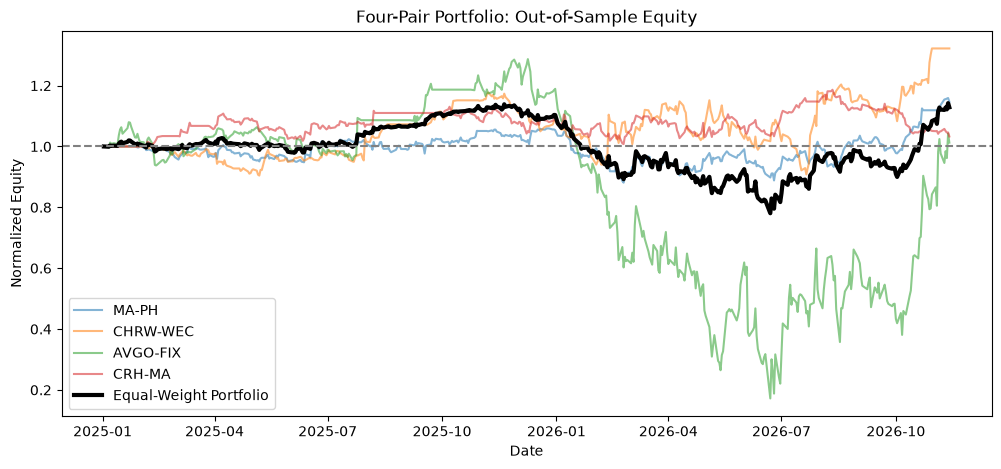

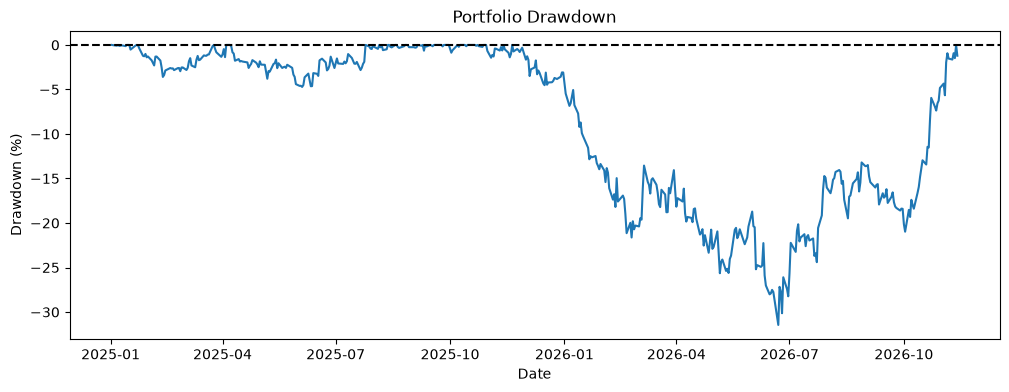

In [30]:

pair_names = ["MA-PH", "CHRW-WEC", "AVGO-FIX", "CRH-MA"]

initial_portfolio_capital = 10000
weight = 1 / len(pair_names)

normalized_equities = pd.DataFrame()
portfolio_pnl = pd.Series(0.0, index=test.index)

for pair in pair_names:
    daily = all_backtests[pair]["daily_results"]

    starting_capital = daily["Equity"].iloc[0] - daily["Net P&L"].iloc[0]

    normalized_equities[pair] = daily["Equity"] / starting_capital

    portfolio_pnl += (
        daily["Net P&L"] / starting_capital
        * initial_portfolio_capital * weight
    )

portfolio_equity = initial_portfolio_capital + portfolio_pnl.cumsum()

portfolio_returns = portfolio_equity.pct_change().fillna(0)

portfolio_total_return = (
    portfolio_equity.iloc[-1] / initial_portfolio_capital - 1
)

portfolio_annual_return = (
    (1 + portfolio_total_return) **
    (252 / (len(portfolio_equity) - 1)) - 1
)

portfolio_volatility = portfolio_returns.std() * np.sqrt(252)

portfolio_sharpe = (
    portfolio_returns.mean() / portfolio_returns.std()
) * np.sqrt(252)

portfolio_peak = portfolio_equity.cummax()

portfolio_drawdown = portfolio_equity / portfolio_peak - 1

portfolio_max_drawdown = portfolio_drawdown.min()

print("Portfolio Total Return:", round(portfolio_total_return * 100, 2), "%")
print("Portfolio Annualized Return:", round(portfolio_annual_return * 100, 2), "%")
print("Portfolio Volatility:", round(portfolio_volatility * 100, 2), "%")
print("Portfolio Sharpe:", round(portfolio_sharpe, 3))
print("Portfolio Max Drawdown:", round(portfolio_max_drawdown * 100, 2), "%")
print("Portfolio Net P&L:", round(portfolio_pnl.sum(), 2))

plt.figure(figsize=(12, 5))

for pair in pair_names:
    plt.plot(
        normalized_equities.index,
        normalized_equities[pair],
        label=pair,
        alpha=0.55
    )

plt.plot(
    portfolio_equity.index,
    portfolio_equity / initial_portfolio_capital,
    label="Equal-Weight Portfolio",
    color="black",
    linewidth=3
)

plt.axhline(1, color="gray", linestyle="--")
plt.title("Four-Pair Portfolio: Out-of-Sample Equity")
plt.xlabel("Date")
plt.ylabel("Normalized Equity")
plt.legend()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(portfolio_drawdown.index, portfolio_drawdown * 100)
plt.axhline(0, color="black", linestyle="--")
plt.title("Portfolio Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.show()